In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


In [13]:

df = pd.read_csv("uber.csv")

print(df.head())


   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [6]:

df.drop(columns=["Unnamed: 0", "key"], errors="ignore", inplace=True)

df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)

df.dropna(inplace=True)

df = df[
    (df["fare_amount"] > 0) &
    (df["passenger_count"].between(1, 6)) &
    (df["pickup_longitude"].between(-75, -72)) &
    (df["dropoff_longitude"].between(-75, -72)) &
    (df["pickup_latitude"].between(40, 42)) &
    (df["dropoff_latitude"].between(40, 42))
].copy()

df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year
df["weekday"] = df["pickup_datetime"].dt.dayofweek

lat1 = np.radians(df["pickup_latitude"])
lat2 = np.radians(df["dropoff_latitude"])
lon1 = np.radians(df["pickup_longitude"])
lon2 = np.radians(df["dropoff_longitude"])

a = (
    np.sin((lat2 - lat1) / 2) ** 2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin((lon2 - lon1) / 2) ** 2
)

df["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))
df = df[df["distance_km"] > 0].copy()

print("Dataset after preprocessing:", df.shape)
print(df.head())


Dataset after preprocessing: (193063, 13)
   fare_amount           pickup_datetime  pickup_longitude  pickup_latitude  \
0          7.5 2015-05-07 19:52:06+00:00        -73.999817        40.738354   
1          7.7 2009-07-17 20:04:56+00:00        -73.994355        40.728225   
2         12.9 2009-08-24 21:45:00+00:00        -74.005043        40.740770   
3          5.3 2009-06-26 08:22:21+00:00        -73.976124        40.790844   
4         16.0 2014-08-28 17:47:00+00:00        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  hour  day  month  \
0         -73.999512         40.723217                1    19    7      5   
1         -73.994710         40.750325                1    20   17      7   
2         -73.962565         40.772647                1    21   24      8   
3         -73.965316         40.803349                3     8   26      6   
4         -73.973082         40.761247                5    17   28      8   

   year  weekday  di

In [14]:
print("Dataset shape:", df.shape)



Dataset shape: (200000, 9)


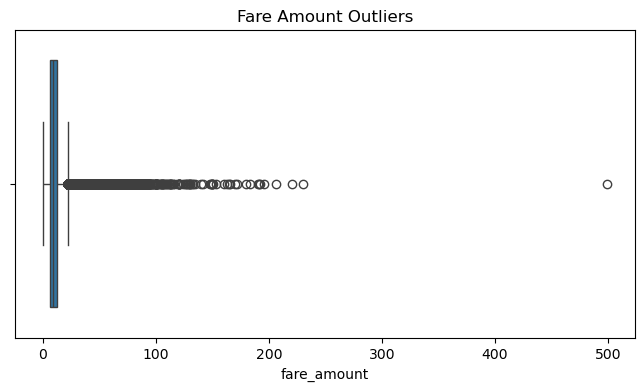

Number of outliers: 16517
Shape after removing outliers: (176546, 13)


In [7]:

plt.figure(figsize=(8, 4))
sns.boxplot(x=df["fare_amount"])
plt.title("Fare Amount Outliers")
plt.show()

Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)
IQR = Q3 - Q1

lower = max(0, Q1 - 1.5 * IQR)
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["fare_amount"] < lower) |
    (df["fare_amount"] > upper)
]

print("Number of outliers:", len(outliers))

df = df[df["fare_amount"].between(lower, upper)].copy()
print("Shape after removing outliers:", df.shape)


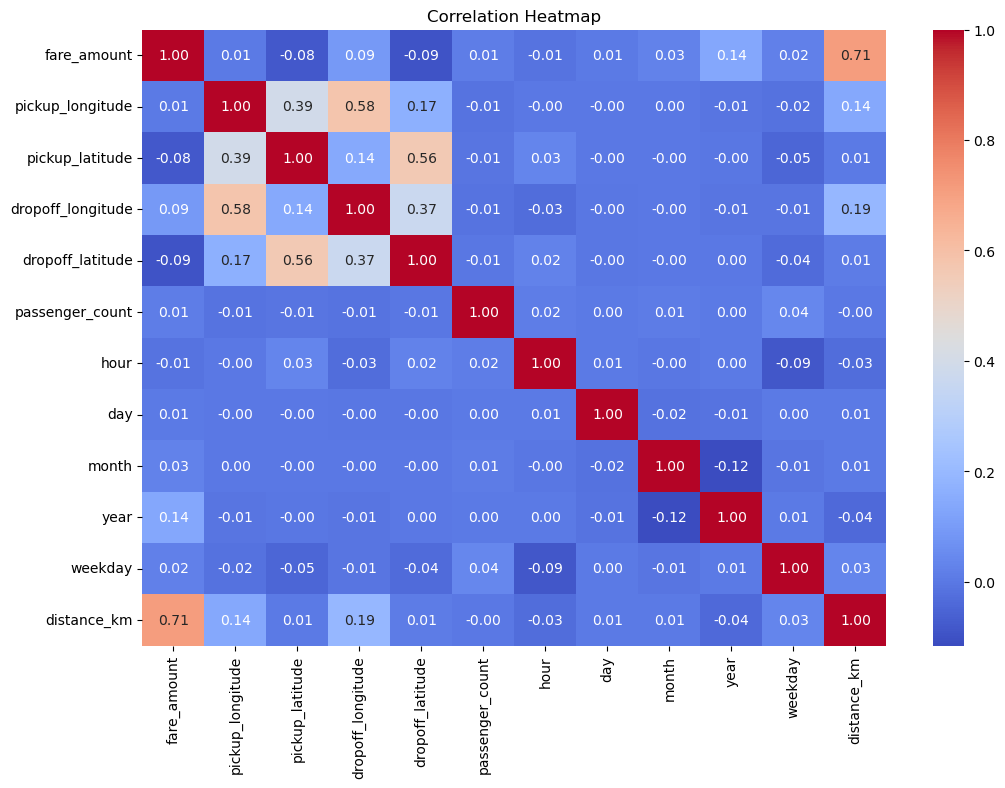

fare_amount          1.000000
pickup_longitude     0.006241
pickup_latitude     -0.083255
dropoff_longitude    0.092935
dropoff_latitude    -0.094292
passenger_count      0.012925
hour                -0.013066
day                  0.006583
month                0.026727
year                 0.135766
weekday              0.020459
distance_km          0.709875
Name: fare_amount, dtype: float64


In [8]:

plt.figure(figsize=(12, 8))
sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True, cmap="coolwarm", fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

print(df.select_dtypes(include=np.number).corr()["fare_amount"])


In [9]:

features = [
    "pickup_longitude", "pickup_latitude",
    "dropoff_longitude", "dropoff_latitude",
    "passenger_count", "hour", "day", "month",
    "year", "weekday", "distance_km"
]

X = df[features]
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 141236
Testing samples: 35310


In [10]:

models = {
    "Linear Regression": make_pipeline(
        StandardScaler(), LinearRegression()
    ),
    "Ridge Regression": make_pipeline(
        StandardScaler(), Ridge(alpha=1.0)
    ),
    "Lasso Regression": make_pipeline(
        StandardScaler(), Lasso(alpha=0.01, max_iter=10000)
    )
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "R2 Score": r2_score(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))


               Model  R2 Score    RMSE     MAE
0  Linear Regression    0.5781  2.6944  1.8134
1   Ridge Regression    0.5781  2.6944  1.8134
2   Lasso Regression    0.5777  2.6958  1.8159


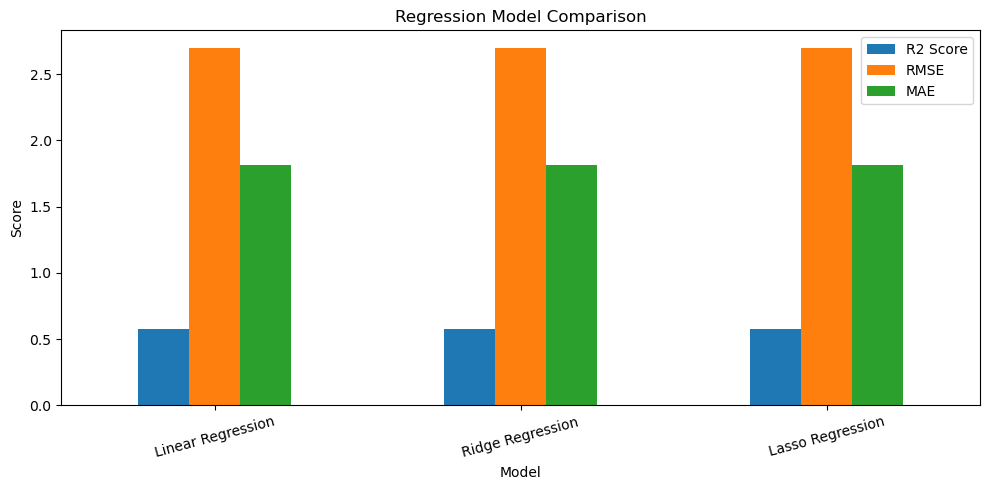

In [11]:

results_df.set_index("Model")[["R2 Score", "RMSE", "MAE"]].plot(
    kind="bar", figsize=(10, 5)
)

plt.title("Regression Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [12]:

sample = X_test.iloc[[0]]

predicted_fare = models["Linear Regression"].predict(sample)[0]

print("Actual fare:", round(y_test.iloc[0], 2))
print("Predicted fare:", round(predicted_fare, 2))


Actual fare: 11.3
Predicted fare: 6.78
